In [1]:
import jax
import jax.numpy as jnp
import numpy as np
import matplotlib.pyplot as plt

from lib import neurons, input_gen, driver, utils

In [ ]:
nd, ns, n, b, bk, beta = 200, 300, 10, 2., 5.5, 13.5153
# nd, ns, n, b, bk, beta = 200, 300, 10, 2., 3.5, 3.7989
bla = jnp.sqrt(2.)*jax.scipy.special.erfinv(1-2*n/nd) # bias - lambda
f_exp = n/nd
age_max = int(0.5/f_exp)
gamma = 1 - 1/(4*age_max)  # 4 times the expected age
shift = bla
b = b - shift*1. # reference values are from previous code without shift, where wx2 = 1
bk = bk - shift*1.

rng = jax.random.PRNGKey(333)
rng, rng1, rng2 = jax.random.split(rng, 3)

hyper = neurons.HyperConfig2(nd=nd, ns=ns, n=n, b=b, bk=bk, beta=beta, age_max=age_max, gamma=gamma, shift=shift)
hyperD = neurons.HyperDynConfig2(b=b, bk=bk, beta=beta, age_max=age_max, gamma=gamma, shift=shift)
neuron = neurons.Neuron_Decay_Int2(hyper)
# xs_gen = input_gen.Normal(nd=hyper.nd, ns=hyper.ns)
xs_gen = input_gen.Normal_random_scaled(nd=hyper.nd, ns=hyper.ns, rng=rng1)

# my_driver = driver.Driver2_age_wx2_record(
#     neuron=neuron,
#     xs_generator=xs_gen,
#     rng=rng2,
#     hyperD=hyperD,
#     initial_state=None,
#     resample_every=1000
# )

my_driver = driver.Driver2_bScan(
    neuron=neuron,
    xs_generator=xs_gen,
    rng=rng2,
    hyperD=hyperD,
    initial_state=None,
    resample_every=1000,
    n_tested_patterns=1000,
)

In [52]:
# n_steps = 30000
# my_driver.run(n_steps=n_steps)
my_driver.run(
    n_init_steps=8000,
    n_steps_phase1=3000,
    n_steps_phase2=20000,
    n_steps_phase3=10000,
    test_every_phase3=50,
    bs=jnp.array([b]),
)

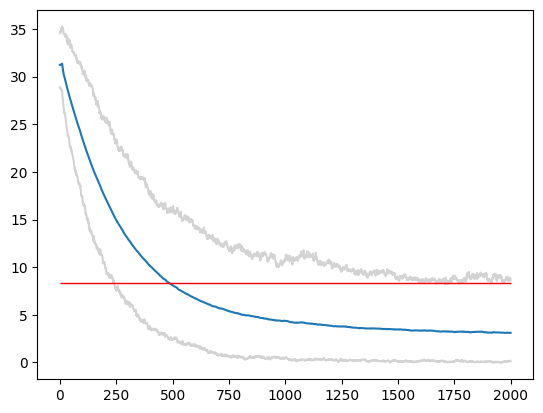

In [53]:
mean = np.mean(my_driver.transient_record, axis=-1)
lower = np.percentile(my_driver.transient_record, 1, axis=-1)
upper = np.percentile(my_driver.transient_record, 99, axis=-1)

steady_upper = np.percentile(my_driver.steady_record, 99, axis=-1)
steady_upper = np.mean(steady_upper, axis=0)

plt.plot(upper, color='lightgrey')
plt.plot(lower, color='lightgrey')
plt.plot(mean)
plt.hlines(steady_upper, 0, 2000, colors='red', linestyles='-', linewidth=1)

In [7]:
tmp = xs_gen.scale_mat
(jnp.sum(tmp, axis=-1)/jnp.linalg.norm(tmp, axis=-1))**2

Array([200.79303, 191.29881, 195.33438, 194.07106, 192.92957, 196.72293,
       193.51343, 193.73389, 198.31975, 189.10835, 192.82364, 190.44334,
       195.21457, 192.79419, 185.22249, 195.79071, 197.03693, 193.07292,
       194.77971, 195.82103, 203.30351, 193.72163, 195.05159, 189.61732,
       187.47466, 183.47447, 201.56961, 191.68921, 190.73874, 181.97191,
       185.87692, 189.09103, 183.02588, 187.92496, 183.16188, 191.23311,
       190.74538, 195.13148, 194.59515, 199.63615, 192.98218, 186.46439,
       202.70622, 191.21718, 187.98354, 196.27362, 193.30017, 195.2259 ,
       187.17067, 178.52315, 197.15427, 195.52031, 190.80496, 188.80061,
       194.70691, 192.80301, 197.7933 , 193.099  , 189.07402, 185.1581 ,
       200.30597, 193.67084, 186.83266, 195.12572, 191.74693, 190.06398,
       188.86375, 196.01709, 183.51022, 194.8693 , 188.88605, 195.832  ,
       205.2342 , 196.68494, 196.15633, 192.07332, 195.99896, 195.52303,
       189.07085, 189.66714, 198.82257, 196.12648, 

(0.0, 1000.0)

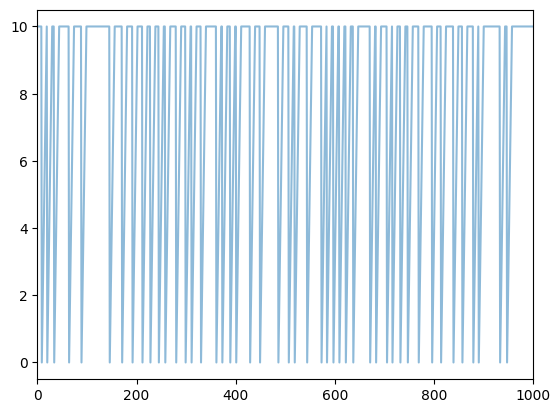

In [24]:
for i in range(1):
    plt.plot(my_driver.age_record[:, i], alpha=0.5)
# plt.hlines(f_exp+delta_th, 0, n_steps, color='red')
# plt.hlines(f_exp-delta_th, 0, n_steps, color='red')
plt.xlim(00, 1000)

(90.0, 110.0)

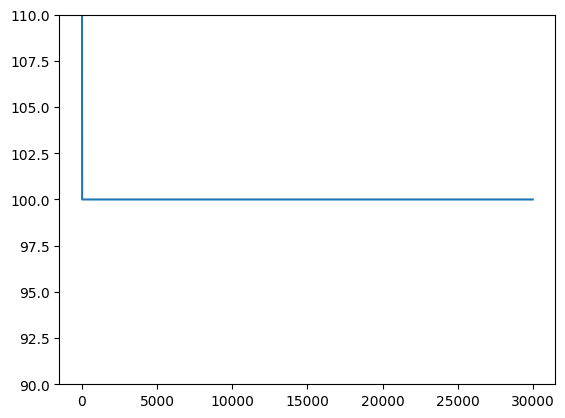

In [25]:
available_num = jnp.sum(my_driver.age_record == age_max, axis=-1)
plt.plot(available_num)
plt.ylim(90, 110)

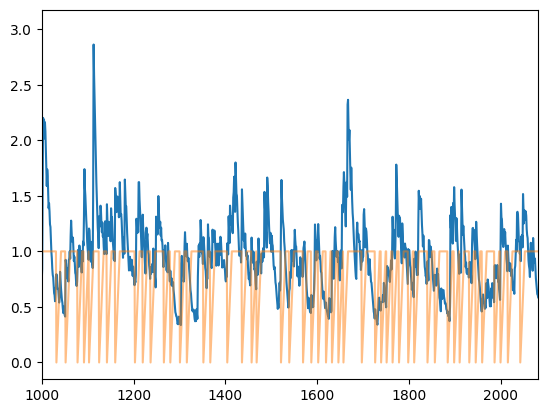

In [36]:
idx=1

for i in range(1):
    plt.plot(my_driver.wx2_record[:, idx], alpha=1)
plt.xlim(1000, 2080)

for i in range(1):
    plt.plot(my_driver.age_record[:, idx]/10, alpha=0.5)

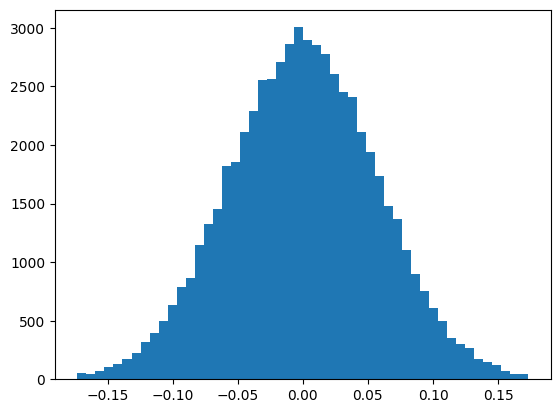

In [37]:
w = my_driver.state.w
plt.hist(np.array(w.flatten()), bins=50);

In [28]:
4*age_max

40